# Day 12 – Dataset V1 Validation and Pipeline Freeze

## Objective

The objective of Day 12 is to validate the preprocessing pipeline and prepare Dataset V1 for subsequent anomaly-detection and forecasting experiments.

The validation includes:

- Review of temporal trends
- Review of candidate anomalies
- Verification of chronological train/validation/test splits
- Temporal leakage checks
- Review of cleaning and resampling decisions
- Documentation of assumptions and mentor-review items
- Dataset V1 freeze

The original raw dataset remains unchanged.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

base_path = r"C:\Users\MESHWA\Downloads\underwater-water-quality-ai-analytics\data\processed"

train_df = pd.read_csv(base_path + r"\train_v1.csv")
val_df = pd.read_csv(base_path + r"\validation_v1.csv")
test_df = pd.read_csv(base_path + r"\test_v1.csv")

for data in [train_df, val_df, test_df]:
    data["timestamp"] = pd.to_datetime(
        data["timestamp"],
        errors="coerce"
    )

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (2291, 11)
Validation: (491, 11)
Test: (491, 11)


## 1. Chronological Split Validation

Dataset V1 uses a chronological 70/15/15 split.

The training period must occur before the validation period, and the validation period must occur before the test period.

This prevents future observations from being used during model training.

In [4]:
print("TRAIN")
print(train_df["timestamp"].min(), "→", train_df["timestamp"].max())

print("\nVALIDATION")
print(val_df["timestamp"].min(), "→", val_df["timestamp"].max())

print("\nTEST")
print(test_df["timestamp"].min(), "→", test_df["timestamp"].max())

train_before_val = (
    train_df["timestamp"].max()
    <= val_df["timestamp"].min()
)

val_before_test = (
    val_df["timestamp"].max()
    <= test_df["timestamp"].min()
)

print("\nTrain before validation:", train_before_val)
print("Validation before test:", val_before_test)

TRAIN
2025-01-01 01:00:00 → 2025-04-07 00:45:00

VALIDATION
2025-04-07 01:45:00 → 2025-04-27 14:45:00

TEST
2025-04-27 15:45:00 → 2025-05-17 23:45:00

Train before validation: True
Validation before test: True


In [5]:
# Leakage check: verify that timestamps do not overlap

train_times = set(train_df["timestamp"])
val_times = set(val_df["timestamp"])
test_times = set(test_df["timestamp"])

print("Train ∩ Validation:",
      len(train_times.intersection(val_times)))

print("Train ∩ Test:",
      len(train_times.intersection(test_times)))

print("Validation ∩ Test:",
      len(val_times.intersection(test_times)))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [6]:
print("Train chronological:",
      train_df["timestamp"].is_monotonic_increasing)

print("Validation chronological:",
      val_df["timestamp"].is_monotonic_increasing)

print("Test chronological:",
      test_df["timestamp"].is_monotonic_increasing)

Train chronological: True
Validation chronological: True
Test chronological: True


## 2. Temporal Leakage Checks

Temporal leakage was checked by verifying that:

- Training timestamps do not overlap with validation timestamps.
- Training timestamps do not overlap with test timestamps.
- Validation timestamps do not overlap with test timestamps.
- Each dataset remains chronologically ordered.
- The training period occurs before the validation period.
- The validation period occurs before the test period.

These checks help prevent future observations from being unintentionally used during model training.

## 3. Temporal Trend Review

Temporal trends identified during Day 10 are reviewed as part of Dataset V1 validation.

The plots are used to identify:

- Sudden spikes
- Sudden drops
- Unusual observations
- Changes in parameter behaviour
- Potential candidate anomalies

Because the timestamps are synthetically generated, these observations are treated as methodological candidate anomalies and not confirmed real-world environmental events.

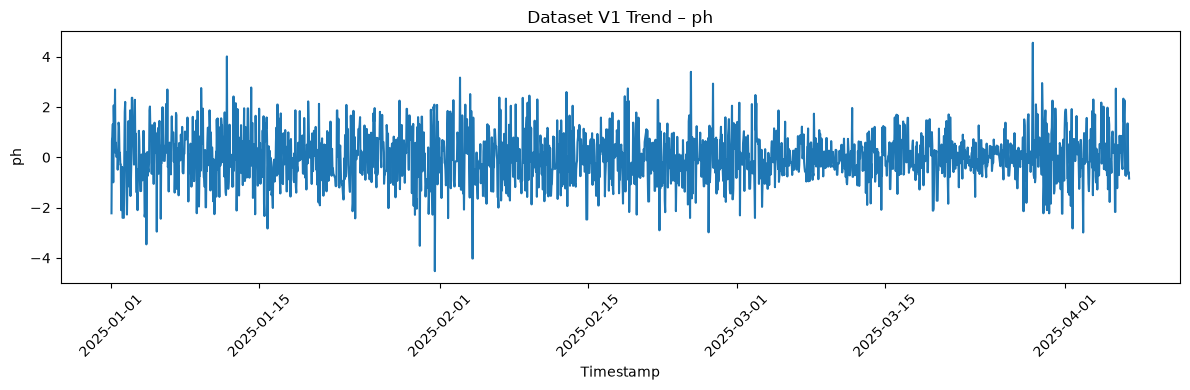

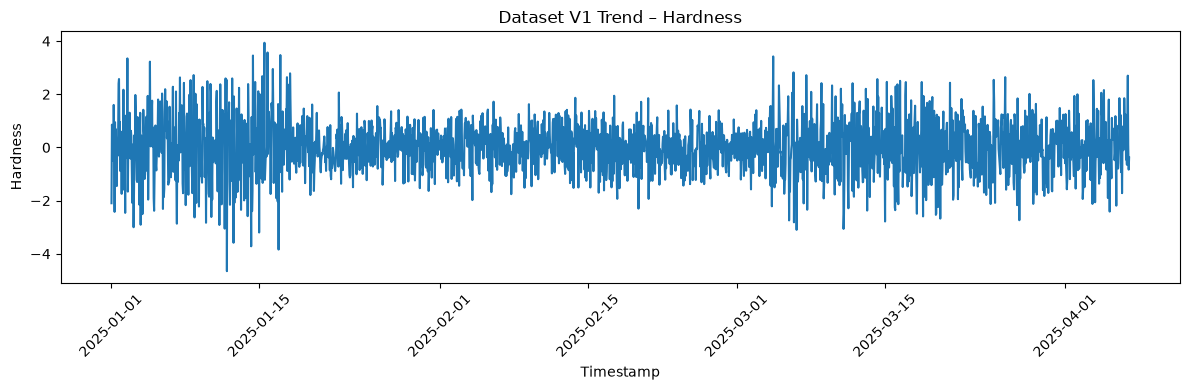

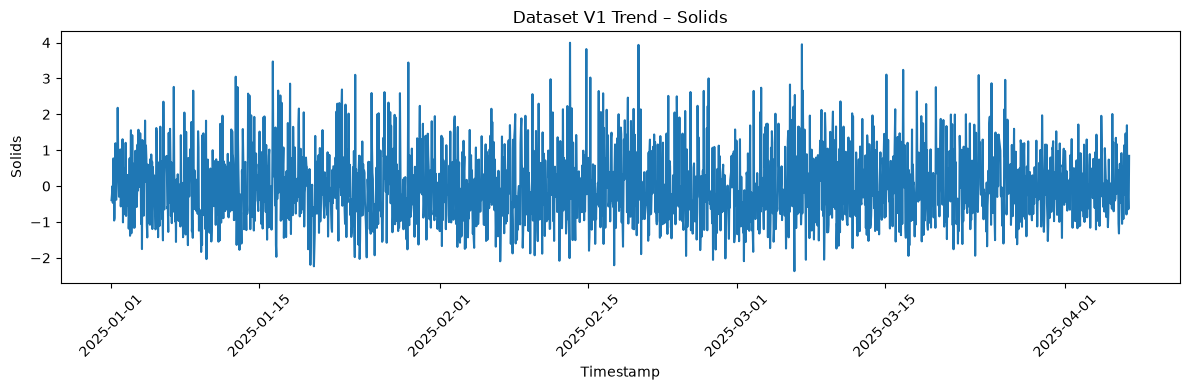

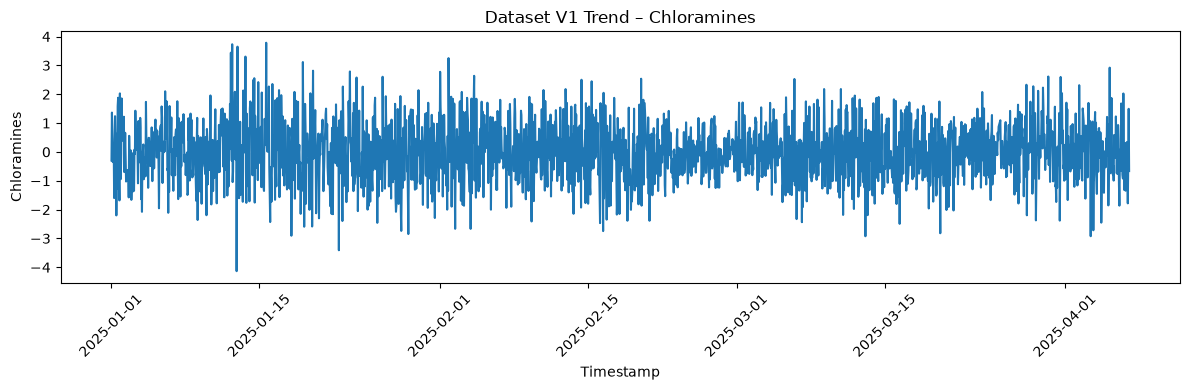

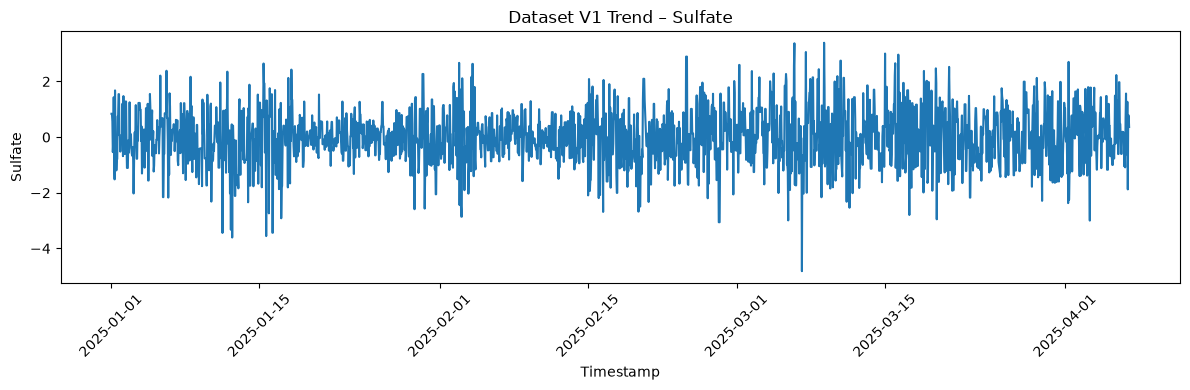

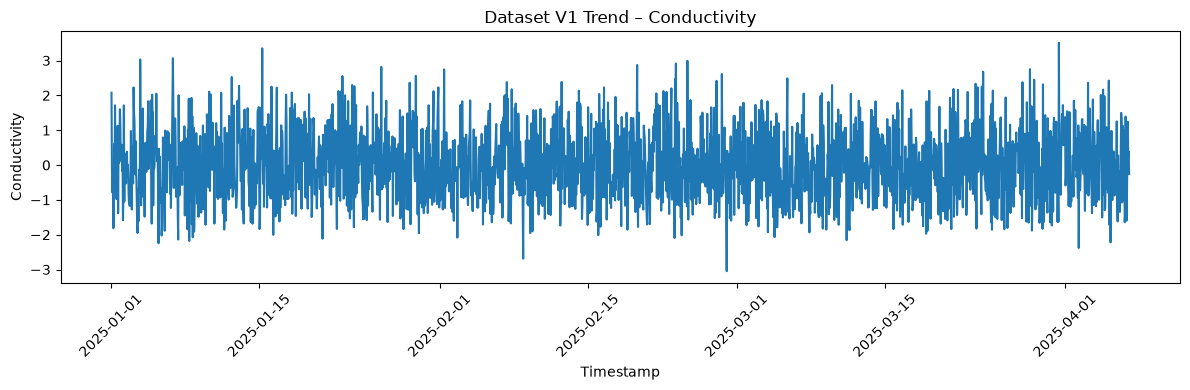

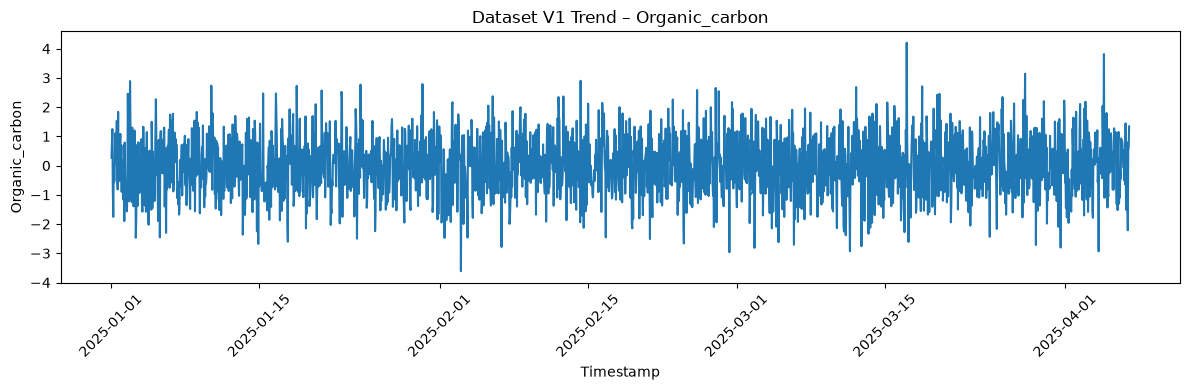

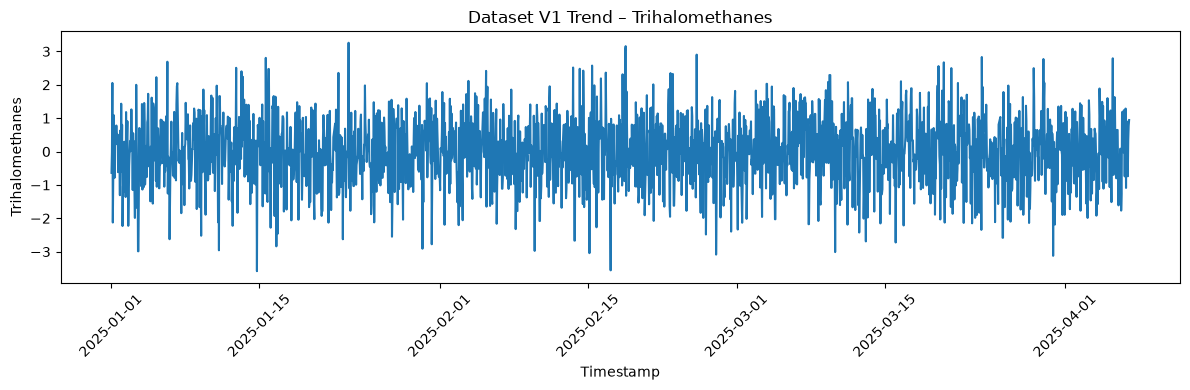

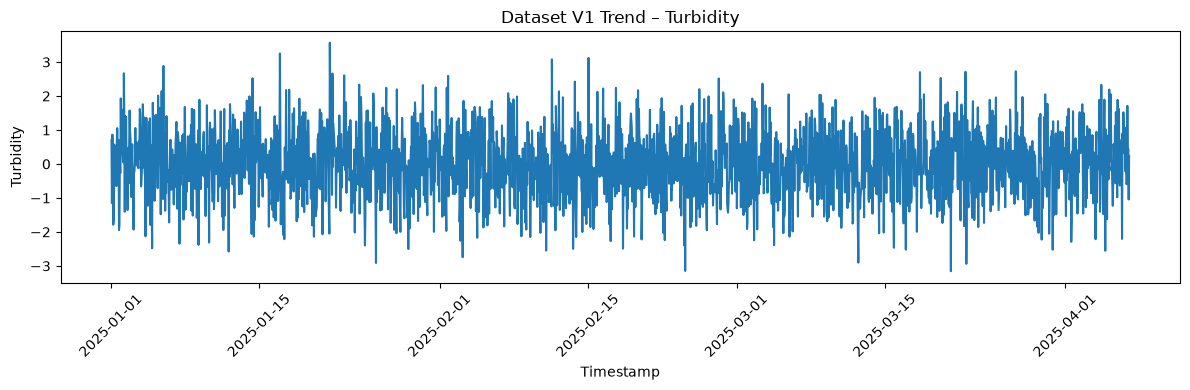

In [7]:
numeric_columns = [
    col for col in train_df.select_dtypes(include=np.number).columns
    if col != "Potability"
]

for column in numeric_columns:
    plt.figure(figsize=(12, 4))

    plt.plot(
        train_df["timestamp"],
        train_df[column]
    )

    plt.title(f"Dataset V1 Trend – {column}")
    plt.xlabel("Timestamp")
    plt.ylabel(column)

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()